Week 11 notebook, DBSCAN and hierarchical clustering, Mike Hembree

Same project as the earlier weeks. The capstone is an early warning model for ICU delirium on MIMIC IV, and the MIMIC part of this notebook runs on the MIMIC IV Clinical Database Demo (100 patients, 140 ICU stays) because the full credentialed access is still pending. The second dataset is the ECAMS EEG data from Massachusetts General Hospital (373 patients, 1189 EEG features, delirium called by the CAM algorithm), the same two datasets as the Milestone One notebooks. Again the clustering never sees the label. DBSCAN needs an eps and a min_samples and marks points as noise if they aren't dense enough, so I used the k distance plots to pick the eps range for each space. For hierarchical clustering I compared ward, complete, average and single linkage and looked at the dendrograms, the cophenetic correlation, and how lopsided the cut is.

In [1]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet, fcluster
from scipy.spatial.distance import pdist

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.family'] = 'serif'

In [2]:
# load both datasets, clustering never sees the delirium label, it is only used afterwards to describe the clusters
feat = pd.read_csv('delirium_features.csv')
mcols = ['anchor_age', 'gender', 'heart_rate', 'sbp', 'dbp', 'resp_rate', 'temp_f', 'spo2', 'gcs_total_min']
Xm = feat[mcols]
ym = feat['delirium_positive']

Xe = pd.read_csv('ecams/features_alldata.csv')
clin = pd.read_csv('ecams/E_CAM_S_Data.csv').sort_values('SubjectID-used_for_feature_extraction').reset_index(drop = True)
ye = clin['CAM algorithm (CAM 1 & 2 , and 3 or 4 SATISFIED - DELIRIUM POSITIVE)'].astype(int)

Xm_filled = SimpleImputer(strategy = 'median').fit_transform(Xm)
spaces = {
    'mimic scaled': StandardScaler().fit_transform(Xm_filled),
    'mimic unscaled': Xm_filled,
    'ecams scaled': StandardScaler().fit_transform(Xe),
    'ecams unscaled': Xe.values,
    'ecams pca 10': PCA(10, random_state = 0).fit_transform(StandardScaler().fit_transform(Xe))
}
labels = {'mimic': ym.values, 'ecams': ye.values}
for k, v in spaces.items():
    print(k, v.shape)

mimic scaled (140, 9)
mimic unscaled (140, 9)
ecams scaled (373, 1189)
ecams unscaled (373, 1189)
ecams pca 10 (373, 10)


mimic scaled median 2.18 90th percentile 2.74
ecams scaled median 26.71 90th percentile 35.6
ecams pca 10 median 16.84 90th percentile 23.17


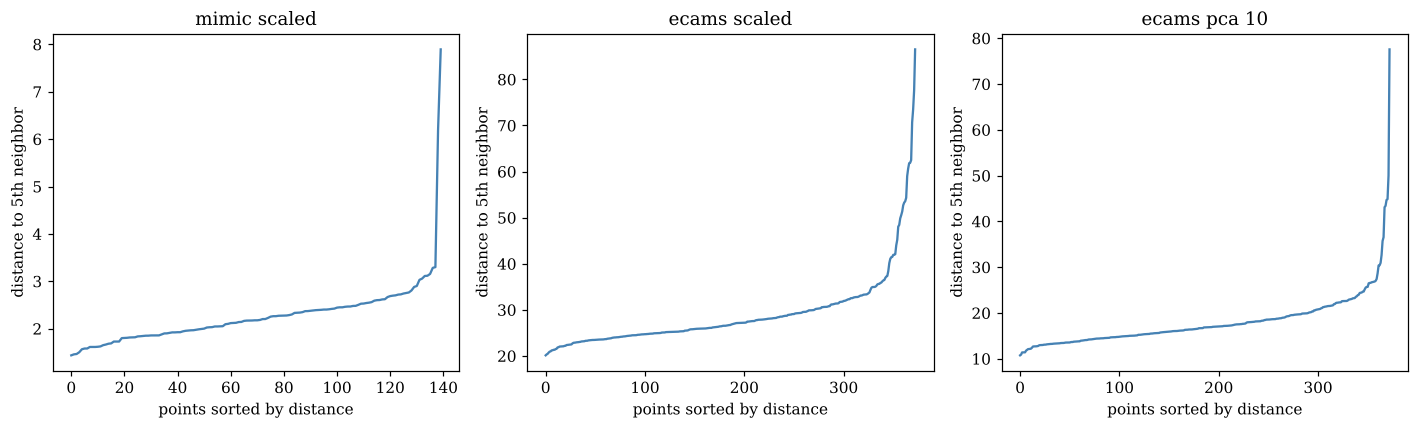

In [3]:
# k distance curves, distance to the 5th nearest neighbor sorted, the knee suggests eps
fig, ax = plt.subplots(1, 3, figsize = (13, 4))
for i, sp in enumerate(['mimic scaled', 'ecams scaled', 'ecams pca 10']):
    Z = spaces[sp]
    d = np.sort(NearestNeighbors(n_neighbors = 5).fit(Z).kneighbors(Z)[0][:, -1])
    ax[i].plot(d, color = 'steelblue')
    ax[i].set_xlabel('points sorted by distance')
    ax[i].set_ylabel('distance to 5th neighbor')
    ax[i].set_title(sp)
    print(sp, 'median', round(np.median(d), 2), '90th percentile', round(np.percentile(d, 90), 2))
plt.tight_layout()
plt.savefig('figs/w11_kdist.png', dpi = 200)
plt.show()

None of the curves has a clean knee. They rise slowly and then shoot up for the last 5 to 10 percent of points. For scaled MIMIC the distance to the 5th neighbor has a median of 2.18 and a 90th percentile of 2.74, for scaled ECAMS it's 26.7 and 35.6, and for the 10 component ECAMS space 16.8 and 23.2. I used those as the center of the eps grids.

In [4]:
# dbscan grid, clusters found, share of noise, silhouette on the clustered points and delirium rate in the noise
rows = []
grids = {'mimic scaled': [1.5, 1.75, 2, 2.25, 2.5, 3], 'ecams scaled': [22, 25, 28, 31, 34, 38, 45], 'ecams pca 10': [13, 15, 17, 19, 21, 24, 28]}
for sp, eps_list in grids.items():
    nm = sp.split()[0]
    Z = spaces[sp]
    for eps in eps_list:
        for ms in [3, 5, 10]:
            lab = DBSCAN(eps = eps, min_samples = ms).fit_predict(Z)
            core = lab != -1
            ncl = len(set(lab[core]))
            row = {'space': sp, 'eps': eps, 'min samples': ms, 'clusters': ncl, 'noise share': 1 - core.mean()}
            row['silhouette'] = silhouette_score(Z[core], lab[core]) if ncl > 1 else np.nan
            row['delirium rate in noise'] = labels[nm][~core].mean() if (~core).sum() > 0 else np.nan
            row['delirium rate in clusters'] = labels[nm][core].mean() if core.sum() > 0 else np.nan
            rows.append(row)
db_tab = pd.DataFrame(rows)
db_tab.to_csv('figs/w11_dbscan_grid.csv', index = False)
db_tab.round(3)

,space,eps,min samples,clusters,noise share,silhouette,delirium rate in noise,delirium rate in clusters
0,mimic scaled,1.50,3,5,0.786,0.426,0.309,0.367
1,mimic scaled,1.50,5,2,0.929,0.163,0.323,0.300
2,mimic scaled,1.50,10,0,1.000,NaN,0.321,NaN
3,mimic scaled,1.75,3,7,0.536,0.218,0.280,0.369
4,mimic scaled,1.75,5,3,0.757,0.361,0.292,0.412
5,mimic scaled,1.75,10,1,0.929,NaN,0.323,0.300
6,mimic scaled,2.00,3,4,0.286,0.109,0.325,0.320
7,mimic scaled,2.00,5,3,0.436,0.182,0.279,0.354
8,mimic scaled,2.00,10,3,0.579,0.255,0.247,0.424
9,mimic scaled,2.25,3,1,0.129,NaN,0.222,0.336


DBSCAN doesn't find real clusters on either dataset. For every eps, either almost every point is in one big cluster with a few noise points, or most of the points are noise. On MIMIC at eps of 2.0 and min_samples of 5 it finds 3 clusters but 44 percent of the stays are noise and the silhouette is 0.18, and at 2.25 and above it's one cluster. On scaled ECAMS the pattern is the same, eps of 22 gives 3 small clusters with 88 percent noise, and eps of 25 and up gives one cluster. The 10 component version is no better, eps of 15 gives two clusters with a silhouette of negative 0.02.

What the noise looks like is more interesting on ECAMS. At an eps of 34 about 9 percent of patients are noise and 79 percent of them are delirious against 67 percent of the clustered patients, and at an eps of 45 it's 83 percent of the 5 percent flagged as noise. These are patients with unusual EEG feature values, and they are somewhat more likely to be delirious. On MIMIC the noise is not enriched, 22 to 35 percent against 32 to 35 percent in the cluster.

In [5]:
# dbscan on the unscaled and scaled mimic data, what the scaling does to the density
rows = []
for sp in ['mimic unscaled', 'mimic scaled']:
    Z = spaces[sp]
    d = np.sort(NearestNeighbors(n_neighbors = 5).fit(Z).kneighbors(Z)[0][:, -1])
    eps = np.percentile(d, 85)
    lab = DBSCAN(eps = eps, min_samples = 5).fit_predict(Z)
    rows.append({'space': sp, 'eps at 85th percentile': eps, 'clusters': len(set(lab)) - (1 if -1 in lab else 0), 'noise share': (lab == -1).mean()})
pd.DataFrame(rows).round(3)

,space,eps at 85th percentile,clusters,noise share
0,mimic unscaled,20.344,1,0.071
1,mimic scaled,2.629,1,0.057


Using the 85th percentile of the 5th neighbor distance as eps gives one cluster on both the unscaled and the scaled MIMIC data, with 7 and 6 percent noise.

In [6]:
# hierarchical clustering, four linkages on both datasets, cophenetic correlation and how lopsided the cut is
rows = []
links = {}
for sp in ['mimic scaled', 'ecams scaled']:
    nm = sp.split()[0]
    Z = spaces[sp]
    dist = pdist(Z)
    for meth in ['ward', 'complete', 'average', 'single']:
        L = linkage(Z, method = meth)
        links[(sp, meth)] = L
        c, _ = cophenet(L, dist)
        for k in [2, 3, 4, 5]:
            lab = fcluster(L, k, criterion = 'maxclust')
            sizes = np.bincount(lab)[1:]
            rows.append({'space': sp, 'linkage': meth, 'k': k, 'cophenetic': c, 'silhouette': silhouette_score(Z, lab), 'largest cluster share': sizes.max() / len(lab), 'smallest cluster': int(sizes.min()), 'ari with delirium': adjusted_rand_score(labels[nm], lab)})
hac_tab = pd.DataFrame(rows)
hac_tab.to_csv('figs/w11_hac.csv', index = False)
hac_tab[hac_tab.k.isin([3, 4])].round(3)

,space,linkage,k,cophenetic,silhouette,largest cluster share,smallest cluster,ari with delirium
1,mimic scaled,ward,3,0.354,0.114,0.400,36,0.006
2,mimic scaled,ward,4,0.354,0.118,0.393,1,0.003
5,mimic scaled,complete,3,0.583,0.466,0.986,1,-0.015
6,mimic scaled,complete,4,0.583,0.066,0.721,1,0.072
9,mimic scaled,average,3,0.788,0.466,0.986,1,-0.015
10,mimic scaled,average,4,0.788,0.221,0.979,1,-0.022
13,mimic scaled,single,3,0.747,0.466,0.986,1,-0.015
14,mimic scaled,single,4,0.747,0.116,0.979,1,0.001
17,ecams scaled,ward,3,0.287,0.095,0.426,68,0.130
18,ecams scaled,ward,4,0.287,0.049,0.426,60,0.052


Linkage choice decides everything. Complete, average and single linkage give a huge cluster and a few tiny ones. For three clusters on ECAMS the largest cluster holds 96.5 percent of the patients with complete linkage and 99.5 percent with average and single, and on MIMIC it's 98.6 percent for all three. Their silhouettes are high (0.32 to 0.48 on ECAMS, 0.47 on MIMIC) but only because almost everything is in one cluster and the other clusters are one or two points, so the number is meaningless. This is chaining. The cophenetic correlation is also higher for those linkages (0.82 for average on ECAMS, 0.79 on MIMIC) than for ward (0.29 and 0.35), because it measures how well the tree preserves the pairwise distances, not whether the clusters are useful. Ward is the only linkage that makes balanced clusters, the largest has 43 percent of ECAMS and 40 percent of MIMIC at three clusters, even though its silhouette is the lowest (0.095 on ECAMS and 0.114 on MIMIC). On MIMIC at four clusters ward splits off one stay on its own.

In [7]:
# ward clusters at k = 4, size and delirium rate in each
rows = []
for sp in ['mimic scaled', 'ecams scaled']:
    nm = sp.split()[0]
    lab = fcluster(links[(sp, 'ward')], 4, criterion = 'maxclust')
    for c in range(1, 5):
        mk = lab == c
        rows.append({'space': sp, 'cluster': c, 'size': int(mk.sum()), 'delirium rate': labels[nm][mk].mean()})
pd.DataFrame(rows).round(3)

,space,cluster,size,delirium rate
0,mimic scaled,1,48,0.271
1,mimic scaled,2,36,0.417
2,mimic scaled,3,55,0.309
3,mimic scaled,4,1,0.000
4,ecams scaled,1,60,0.850
5,ecams scaled,2,86,0.977
6,ecams scaled,3,159,0.453
7,ecams scaled,4,68,0.691


The ward clusters on ECAMS have delirium rates of 85 percent (60 patients), 98 percent (86), 45 percent (159) and 69 percent (68). That is a much wider spread than the overall rate of 68 percent and the cluster with 98 percent is the one that gets most of the delirious patients. The ARI is only 0.13 at three clusters because the groups are different sizes and the rates aren't 0 and 100. On MIMIC the rates are 27, 42 and 31 percent for the three real clusters (48, 36 and 55 stays), so ward finds the same story as K means, a bit of signal but nothing a clinician could use.

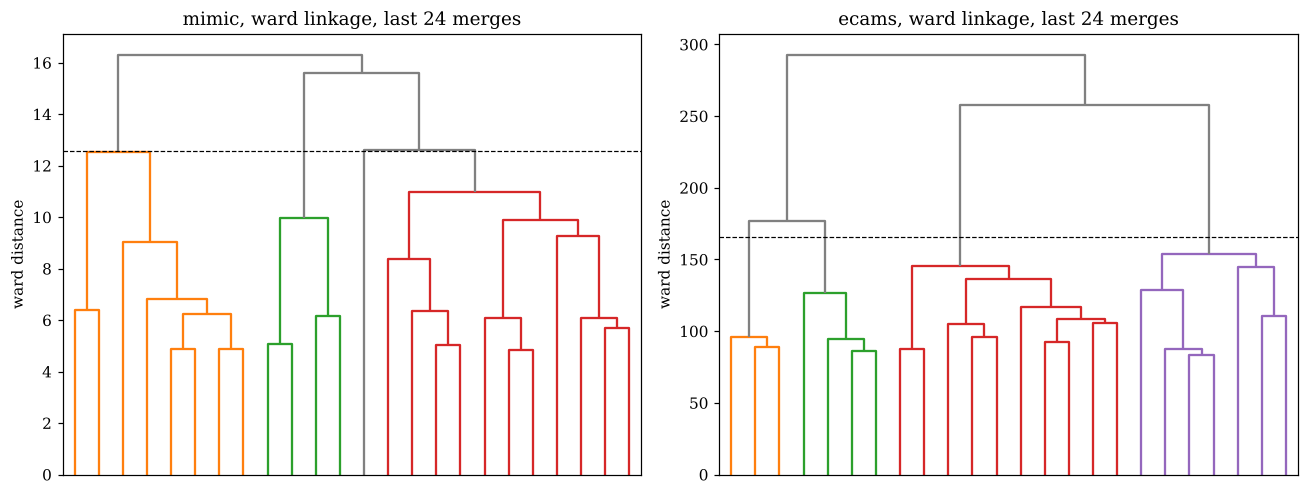

In [8]:
# figure, dendrograms for the ward linkage on both datasets, cut at four clusters
fig, ax = plt.subplots(1, 2, figsize = (12, 4.6))
for i, sp in enumerate(['mimic scaled', 'ecams scaled']):
    L = links[(sp, 'ward')]
    thr = (L[-4, 2] + L[-3, 2]) / 2
    dendrogram(L, truncate_mode = 'lastp', p = 24, ax = ax[i], color_threshold = thr, no_labels = True, above_threshold_color = 'gray')
    ax[i].axhline(thr, color = 'black', linestyle = '--', linewidth = 0.8)
    ax[i].set_ylabel('ward distance')
    ax[i].set_title(sp.split()[0] + ', ward linkage, last 24 merges')
plt.tight_layout()
plt.savefig('figs/w11_dendro.png', dpi = 200)
plt.show()

The ECAMS dendrogram has two big branches that split at a ward distance of about 290, and the four cluster cut is easy to see. The MIMIC tree is much more even, there isn't one height where the cut is obviously right, which matches its low silhouette and cophenetic correlation.

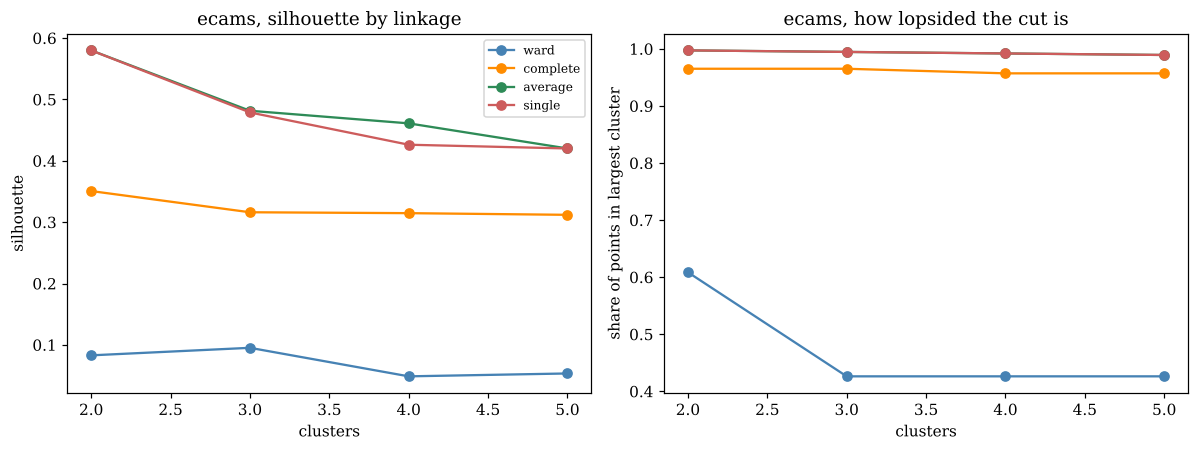

In [9]:
# figure, silhouette against k for the four linkages next to the share of points in the largest cluster
fig, ax = plt.subplots(1, 2, figsize = (11, 4.2))
for meth, c in zip(['ward', 'complete', 'average', 'single'], ['steelblue', 'darkorange', 'seagreen', 'indianred']):
    t = hac_tab[(hac_tab.space == 'ecams scaled') & (hac_tab.linkage == meth)]
    ax[0].plot(t['k'], t['silhouette'], 'o-', color = c, label = meth)
    ax[1].plot(t['k'], t['largest cluster share'], 'o-', color = c, label = meth)
ax[0].set_xlabel('clusters')
ax[0].set_ylabel('silhouette')
ax[0].set_title('ecams, silhouette by linkage')
ax[0].legend(fontsize = 8)
ax[1].set_xlabel('clusters')
ax[1].set_ylabel('share of points in largest cluster')
ax[1].set_title('ecams, how lopsided the cut is')
plt.tight_layout()
plt.savefig('figs/w11_linkage.png', dpi = 200)
plt.show()

The left panel shows the silhouette trap again. Average and single linkage have the highest silhouette on ECAMS (0.48 at three clusters) and the right panel shows their largest cluster holds 99 percent of the patients. Ward is the lowest in silhouette but it's the only one where the largest cluster drops to 43 percent.

To sum up, density based clustering found no stable groups on either dataset, though its noise points are mildly enriched for delirium on ECAMS, and hierarchical clustering only gives useful groups with ward linkage, where the ECAMS clusters range from 45 to 98 percent delirious. Silhouette and cophenetic correlation both favored the linkages that gave one giant cluster, so I wouldn't pick a clustering from those numbers alone.